<a href="https://colab.research.google.com/github/gof0004/Honors-research-seminar/blob/main/Honors_Research_Seminar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!wget -q https://ftp.ncbi.nlm.nih.gov/geo/series/GSE13nnn/GSE13159/matrix/GSE13159_series_matrix.txt.gz
!ls -lh GSE13159_series_matrix.txt.gz

-rw-r--r-- 1 root root 846M Oct  6 15:38 GSE13159_series_matrix.txt.gz


In [2]:
import gzip
from collections import Counter

meta = {}
with gzip.open("GSE13159_series_matrix.txt.gz", "rt") as f:
    for line in f:
        if line.startswith("!series_matrix_table_begin"):
            break
        if line.startswith("!Sample_"):
            parts = line.rstrip("\n").split("\t")
            meta.setdefault(parts[0], []).append([p.strip('"') for p in parts[1:]])

print(len(meta["!Sample_geo_accession"][0]), "samples found")
for key, rows in meta.items():
    for i, row in enumerate(rows):
        counts = Counter(row)
        if 1 < len(counts) <= 30:
            print("\n", key, i)
            for value, n in counts.most_common():
                print("  ", n, value)

2096 samples found

 !Sample_submission_date 0
   1416 Oct 11 2008
   680 Oct 10 2008

 !Sample_last_update_date 0
   1288 Nov 14 2018
   576 Mar 25 2020
   232 Oct 07 2011

 !Sample_characteristics_ch1 0
   1556 sample type: bone marrow
   540 sample type: peripheral blood

 !Sample_characteristics_ch1 1
   448 leukemia class: CLL
   351 leukemia class: AML with normal karyotype + other abnormalities
   237 leukemia class: c-ALL/Pre-B-ALL without t(9;22)
   206 leukemia class: MDS
   174 leukemia class: T-ALL
   122 leukemia class: c-ALL/Pre-B-ALL with t(9;22)
   76 leukemia class: CML
   74 leukemia class: Non-leukemia and healthy bone marrow
   70 leukemia class: Pro-B-ALL with t(11q23)/MLL
   58 leukemia class: ALL with t(12;21)
   48 leukemia class: AML complex aberrant karyotype
   40 leukemia class: ALL with hyperdiploid karyotype
   40 leukemia class: AML with t(8;21)
   38 leukemia class: AML with t(11q23)/MLL
   37 leukemia class: AML with t(15;17)
   36 leukemia class: ALL w

In [3]:
import pandas as pd

ids = meta["!Sample_geo_accession"][0]
sample_type = meta["!Sample_characteristics_ch1"][0]
leuk_class = meta["!Sample_characteristics_ch1"][1]

labels = pd.DataFrame({
    "gsm": ids,
    "sample_type": [s.replace("sample type: ", "") for s in sample_type],
    "leukemia_class": [c.replace("leukemia class: ", "") for c in leuk_class],
})

def group(c):
    if c == "Non-leukemia and healthy bone marrow":
        return "Control"
    if "ALL" in c and "T-ALL" not in c and "mature" not in c:
        return "B-ALL"
    return None

labels["group"] = labels["leukemia_class"].map(group)
sel = labels.dropna(subset=["group"]).copy()

print(sel["group"].value_counts())
print()
print(pd.crosstab(sel["group"], sel["sample_type"]))

group
B-ALL      563
Control     74
Name: count, dtype: int64

sample_type  bone marrow  peripheral blood
group                                     
B-ALL                528                35
Control               73                 1


In [4]:
!wget -q https://ftp.ncbi.nlm.nih.gov/geo/platforms/GPLnnn/GPL570/annot/GPL570.annot.gz

import gzip, io
import pandas as pd

genes = ["MYC","BCL2","BCL2L1","MCL1","BIRC5","CCND1","CCND2","CDC25A","PIM1","SOCS3"]

with gzip.open("GPL570.annot.gz", "rt", errors="replace") as f:
    lines = f.read().splitlines()
begin = next(i for i, l in enumerate(lines) if l.startswith("!platform_table_begin"))
end = next(i for i, l in enumerate(lines) if l.startswith("!platform_table_end"))
annot = pd.read_csv(io.StringIO("\n".join(lines[begin+1:end])), sep="\t", low_memory=False)

sym_col = [c for c in annot.columns if c.lower() == "gene symbol"][0]
annot["symbol_list"] = annot[sym_col].fillna("").str.split(" /// ")
probes = annot.explode("symbol_list")
probes = probes[probes["symbol_list"].isin(genes)][["ID", "symbol_list"]]
probes = probes.rename(columns={"symbol_list": "gene"})

print(probes.sort_values("gene").to_string(index=False))
print()
print(probes["gene"].value_counts())
print("Missing genes:", [g for g in genes if g not in set(probes["gene"])])

          ID   gene
   207004_at   BCL2
 207005_s_at   BCL2
   203685_at   BCL2
 203684_s_at   BCL2
 206665_s_at BCL2L1
 215037_s_at BCL2L1
   212312_at BCL2L1
   231228_at BCL2L1
 202095_s_at  BIRC5
   202094_at  BIRC5
 210334_x_at  BIRC5
  1555826_at  BIRC5
   208712_at  CCND1
 208711_s_at  CCND1
 200952_s_at  CCND2
 200951_s_at  CCND2
 200953_s_at  CCND2
 231259_s_at  CCND2
1555772_a_at CDC25A
 204696_s_at CDC25A
   204695_at CDC25A
 200798_x_at   MCL1
 200797_s_at   MCL1
   214056_at   MCL1
   214057_at   MCL1
 200796_s_at   MCL1
   227175_at   MCL1
 202431_s_at    MYC
   209193_at   PIM1
   214105_at  SOCS3
   227697_at  SOCS3
   206359_at  SOCS3
 206360_s_at  SOCS3

gene
MCL1      6
BIRC5     4
BCL2L1    4
CCND2     4
BCL2      4
SOCS3     4
CDC25A    3
CCND1     2
MYC       1
PIM1      1
Name: count, dtype: int64
Missing genes: []


In [5]:
import gzip
import pandas as pd

probe_ids = set(probes["ID"])
rows = {}
with gzip.open("GSE13159_series_matrix.txt.gz", "rt") as f:
    in_table = False
    for line in f:
        if line.startswith("!series_matrix_table_begin"):
            in_table = True
            header = [h.strip('"') for h in next(f).rstrip("\n").split("\t")]
            continue
        if not in_table:
            continue
        if line.startswith("!series_matrix_table_end"):
            break
        pid, rest = line.split("\t", 1)
        pid = pid.strip('"')
        if pid in probe_ids:
            rows[pid] = rest.rstrip("\n").split("\t")

expr = pd.DataFrame(rows, index=header[1:]).apply(pd.to_numeric, errors="coerce")
print("All samples x probes:", expr.shape)

expr = expr.loc[sel["gsm"]]
print("Selected samples x probes:", expr.shape)
print("Missing values:", int(expr.isna().sum().sum()))
print("Value range:", round(expr.min().min(), 2), "to", round(expr.max().max(), 2))

probe_gene = probes.set_index("ID")["gene"]
means = expr.mean()
best = means.groupby(probe_gene.reindex(means.index)).idxmax()
print("\nProbe chosen for each gene:")
print(best.to_string())

panel = expr[best.values].copy()
panel.columns = best.index
panel.insert(0, "group", sel.set_index("gsm").loc[panel.index, "group"].values)
panel.to_csv("stat3_panel_expression.csv")

print("\nAverage expression, B-ALL vs Control:")
print(panel.groupby("group").mean().T.round(2))

All samples x probes: (2096, 33)
Selected samples x probes: (637, 33)
Missing values: 0
Value range: 0.0 to 0.89

Probe chosen for each gene:
gene
BCL2        203685_at
BCL2L1      212312_at
BIRC5     202095_s_at
CCND1     208711_s_at
CCND2     200953_s_at
CDC25A      204695_at
MCL1      200797_s_at
MYC       202431_s_at
PIM1        209193_at
SOCS3       227697_at

Average expression, B-ALL vs Control:
group   B-ALL  Control
gene                  
BCL2     0.53     0.42
BCL2L1   0.55     0.58
BIRC5    0.54     0.63
CCND1    0.21     0.21
CCND2    0.66     0.67
CDC25A   0.40     0.47
MCL1     0.81     0.84
MYC      0.65     0.66
PIM1     0.57     0.63
SOCS3    0.38     0.52


In [6]:
for key, rows in meta.items():
    if any(w in key.lower() for w in ["process", "descr", "protocol", "extract", "label", "hyb"]):
        for row in rows:
            vals = Counter(row)
            print("\n", key, "-", len(vals), "unique value(s)")
            for v, n in vals.most_common(3):
                print("  ", n, v[:400])

print("\nSpread of the 10 chosen genes:")
print(panel.drop(columns="group").describe().T[["min", "50%", "max"]].round(3))


 !Sample_treatment_protocol_ch1 - 1 unique value(s)
   2096 Samples are from untreated patients.

 !Sample_growth_protocol_ch1 - 1 unique value(s)
   2096 not applicable

 !Sample_extract_protocol_ch1 - 1 unique value(s)
   2096 The total RNA was purified either with Qiagen RNeasy Mini kits (Qiagen, Hilden, Germany) or with TRIzol-based protocols

 !Sample_label_ch1 - 1 unique value(s)
   2096 biotin

 !Sample_label_protocol_ch1 - 1 unique value(s)
   2096 For each sample preparation, total RNA was converted into double-stranded cDNA by reverse transcription using a cDNA Synthesis System kit including an oligo(dT)24 – T7 primer (Roche Applied Science, Mannheim, Germany) and Poly-A control transcripts (Affymetrix, Santa Clara, CA, USA). The generated cRNA was purified using the GeneChip Sample Cleanup Module (Affymetrix) and quantified using the Nano

 !Sample_hyb_protocol - 1 unique value(s)
   2096 Hybridization, washing, and staining protocols, respectively, were performed on Affyme

In [7]:
import textwrap
print(textwrap.fill(meta["!Sample_data_processing"][0][0], 120))

Data pre-processing included a summarization and quantile normalization step to generate probe set level signal
intensities for each microarray experiment and was performed as previously published by Liu WM et al. PQN and DQN:
algorithms for expression microarrays. J.Theor.Biol. 2006;243:273-278.


In [8]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, balanced_accuracy_score

X = panel.drop(columns="group").values
gene_names = list(panel.drop(columns="group").columns)
y = (panel["group"] == "B-ALL").astype(int).values

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {
    "Logistic regression": make_pipeline(StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Random forest": RandomForestClassifier(n_estimators=500,
        class_weight="balanced", random_state=42, n_jobs=-1),
}

rng = np.random.default_rng(42)
for name, model in models.items():
    p = cross_val_predict(model, X, y, cv=cv, method="predict_proba")[:, 1]
    auc = roc_auc_score(y, p)
    boots = []
    for _ in range(1000):
        idx = rng.integers(0, len(y), len(y))
        if len(set(y[idx])) == 2:
            boots.append(roc_auc_score(y[idx], p[idx]))
    lo, hi = np.percentile(boots, [2.5, 97.5])
    bal = balanced_accuracy_score(y, (p >= 0.5).astype(int))
    print(f"{name}: AUROC {auc:.3f} (95% CI {lo:.3f}-{hi:.3f}), balanced accuracy {bal:.3f}")

print("\nEach gene alone (AUROC; 0.5 = no signal, above 0.5 = higher in B-ALL):")
for j, g in enumerate(gene_names):
    print(f"  {g:7s} {roc_auc_score(y, X[:, j]):.3f}")

Logistic regression: AUROC 0.928 (95% CI 0.901-0.955), balanced accuracy 0.860
Random forest: AUROC 0.973 (95% CI 0.959-0.986), balanced accuracy 0.805

Each gene alone (AUROC; 0.5 = no signal, above 0.5 = higher in B-ALL):
  BCL2    0.744
  BCL2L1  0.413
  BIRC5   0.168
  CCND1   0.522
  CCND2   0.611
  CDC25A  0.261
  MCL1    0.185
  MYC     0.454
  PIM1    0.300
  SOCS3   0.213


In [9]:
import numpy as np
import gzip

col_gsm = header[1:]
sel_idx = [col_gsm.index(g) for g in sel["gsm"]]

def to_float(fields):
    try:
        return np.array([fields[i] for i in sel_idx], dtype=np.float32)
    except ValueError:
        return pd.to_numeric(pd.Series([fields[i] for i in sel_idx]), errors="coerce").values.astype(np.float32)

probe_names, mat = [], []
with gzip.open("GSE13159_series_matrix.txt.gz", "rt") as f:
    in_table = False
    for line in f:
        if line.startswith("!series_matrix_table_begin"):
            in_table = True
            next(f)
            continue
        if not in_table:
            continue
        if line.startswith("!series_matrix_table_end"):
            break
        pid, rest = line.split("\t", 1)
        probe_names.append(pid.strip('"'))
        mat.append(to_float(rest.rstrip("\n").split("\t")))

allprobe = pd.DataFrame(np.vstack(mat), index=probe_names, columns=list(sel["gsm"]))
print("All probes x selected samples:", allprobe.shape)
print("Missing values:", int(allprobe.isna().sum().sum()))

a2 = annot[["ID", "symbol_list"]].explode("symbol_list")
a2 = a2[(a2["symbol_list"].str.len() > 0) & (a2["symbol_list"] != "---")]
a2 = a2[a2["ID"].isin(allprobe.index)]
a2["mean"] = a2["ID"].map(allprobe.mean(axis=1))
best_all = a2.sort_values("mean", ascending=False).drop_duplicates("symbol_list")
genes_all = allprobe.loc[best_all["ID"].values].copy()
genes_all.index = best_all["symbol_list"].values
print("Genes x samples:", genes_all.shape)

ok = all(np.allclose(genes_all.loc[g].values, panel[g].values) for g in gene_names)
print("Matches the 10-gene panel:", ok)
genes_all.to_pickle("all_genes_637.pkl")

All probes x selected samples: (54675, 637)
Missing values: 28665
Genes x samples: (22189, 637)
Matches the 10-gene panel: True


In [10]:
G = genes_all.dropna()
pool = [g for g in G.index if g not in gene_names]
print("Genes available for random sets:", len(pool))

lr = make_pipeline(StandardScaler(),
                   LogisticRegression(max_iter=1000, class_weight="balanced"))
Gt = G[list(panel.index)].T

p_stat3 = cross_val_predict(lr, X, y, cv=cv, method="predict_proba")[:, 1]
stat3_auc = roc_auc_score(y, p_stat3)

rng = np.random.default_rng(42)
random_aucs = []
for i in range(1000):
    pick = rng.choice(pool, size=10, replace=False)
    p = cross_val_predict(lr, Gt[pick].values, y, cv=cv, method="predict_proba")[:, 1]
    random_aucs.append(roc_auc_score(y, p))
    if (i + 1) % 200 == 0:
        print(i + 1, "random sets done")
random_aucs = np.array(random_aucs)

p_emp = (np.sum(random_aucs >= stat3_auc) + 1) / (len(random_aucs) + 1)
print(f"\nSTAT3 panel AUROC: {stat3_auc:.3f}")
print(f"Random sets: min {random_aucs.min():.3f}, median {np.median(random_aucs):.3f}, "
      f"95th percentile {np.percentile(random_aucs, 95):.3f}, max {random_aucs.max():.3f}")
print(f"Random sets scoring at or above STAT3: {int(np.sum(random_aucs >= stat3_auc))} of 1000")
print(f"Empirical p-value: {p_emp:.4f}")
pd.Series(random_aucs).to_csv("random_set_aucs.csv", index=False)

Genes available for random sets: 22179
200 random sets done
400 random sets done
600 random sets done
800 random sets done
1000 random sets done

STAT3 panel AUROC: 0.928
Random sets: min 0.659, median 0.964, 95th percentile 0.994, max 0.998
Random sets scoring at or above STAT3: 742 of 1000
Empirical p-value: 0.7423


In [11]:
marrow = (sel.set_index("gsm").loc[panel.index, "sample_type"] == "bone marrow").values
Xm, ym = X[marrow], y[marrow]
Gm = Gt.iloc[np.where(marrow)[0]]
print("Marrow only:", int(ym.sum()), "B-ALL vs", int((ym == 0).sum()), "controls")

cv_m = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
p_lr = cross_val_predict(lr, Xm, ym, cv=cv_m, method="predict_proba")[:, 1]
rf = RandomForestClassifier(n_estimators=500, class_weight="balanced",
                            random_state=42, n_jobs=-1)
p_rf = cross_val_predict(rf, Xm, ym, cv=cv_m, method="predict_proba")[:, 1]
auc_m = roc_auc_score(ym, p_lr)
print(f"STAT3 panel: logistic AUROC {auc_m:.3f}, random forest AUROC {roc_auc_score(ym, p_rf):.3f}")

rng = np.random.default_rng(42)
aucs_m = []
for i in range(1000):
    pick = rng.choice(pool, size=10, replace=False)
    p = cross_val_predict(lr, Gm[pick].values, ym, cv=cv_m, method="predict_proba")[:, 1]
    aucs_m.append(roc_auc_score(ym, p))
aucs_m = np.array(aucs_m)

print(f"Random sets: median {np.median(aucs_m):.3f}, 95th percentile {np.percentile(aucs_m, 95):.3f}, max {aucs_m.max():.3f}")
print(f"Random sets at or above STAT3: {int(np.sum(aucs_m >= auc_m))} of 1000")
print(f"Empirical p-value: {(np.sum(aucs_m >= auc_m) + 1) / (len(aucs_m) + 1):.4f}")

Marrow only: 528 B-ALL vs 73 controls
STAT3 panel: logistic AUROC 0.944, random forest AUROC 0.975
Random sets: median 0.967, 95th percentile 0.995, max 0.998
Random sets at or above STAT3: 680 of 1000
Empirical p-value: 0.6803


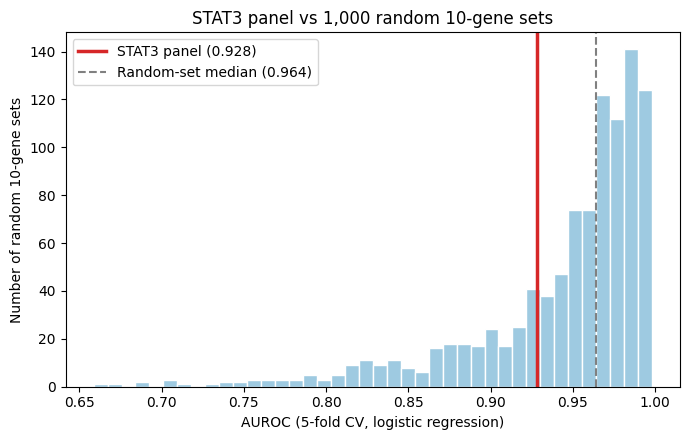

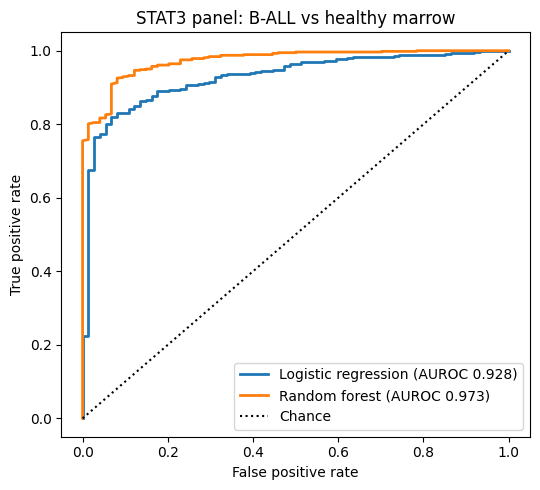

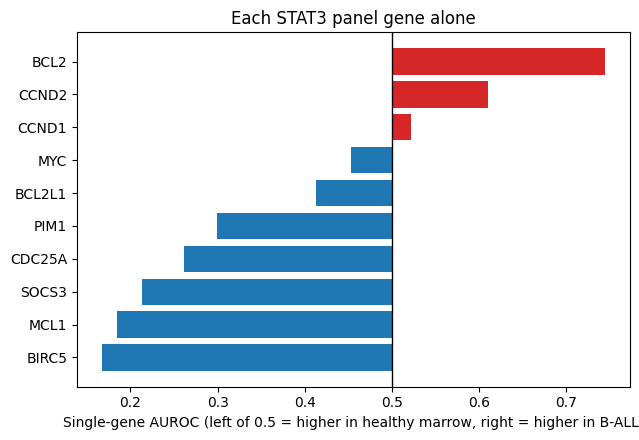

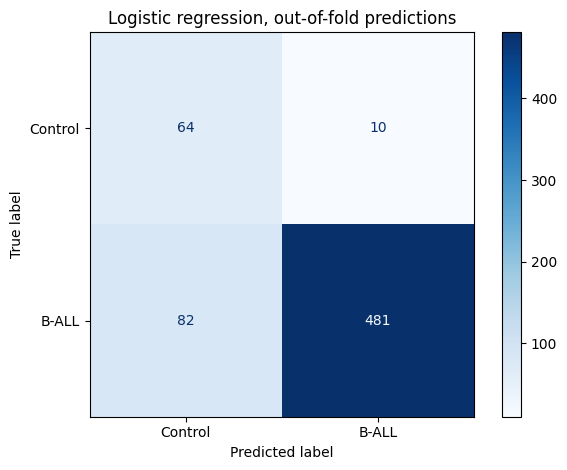

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay

# Figure 1: STAT3 panel vs 1,000 random gene sets
plt.figure(figsize=(7, 4.5))
plt.hist(random_aucs, bins=40, color="#9ecae1", edgecolor="white")
plt.axvline(stat3_auc, color="#d62728", lw=2.5, label=f"STAT3 panel ({stat3_auc:.3f})")
plt.axvline(np.median(random_aucs), color="gray", ls="--",
            label=f"Random-set median ({np.median(random_aucs):.3f})")
plt.xlabel("AUROC (5-fold CV, logistic regression)")
plt.ylabel("Number of random 10-gene sets")
plt.title("STAT3 panel vs 1,000 random 10-gene sets")
plt.legend(); plt.tight_layout()
plt.savefig("fig1_random_sets.png", dpi=300); plt.show()

# Figure 2: ROC curves for the STAT3 panel
rf_full = RandomForestClassifier(n_estimators=500, class_weight="balanced",
                                 random_state=42, n_jobs=-1)
p_rf_all = cross_val_predict(rf_full, X, y, cv=cv, method="predict_proba")[:, 1]
plt.figure(figsize=(5.5, 5))
for name, pp in [("Logistic regression", p_stat3), ("Random forest", p_rf_all)]:
    fpr, tpr, _ = roc_curve(y, pp)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUROC {roc_auc_score(y, pp):.3f})")
plt.plot([0, 1], [0, 1], "k:", label="Chance")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("STAT3 panel: B-ALL vs healthy marrow"); plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig("fig2_roc.png", dpi=300); plt.show()

# Figure 3: each gene alone
gene_auc = np.array([roc_auc_score(y, X[:, j]) for j in range(X.shape[1])])
order = np.argsort(gene_auc)
plt.figure(figsize=(6.5, 4.5))
plt.barh(np.array(gene_names)[order], gene_auc[order] - 0.5, left=0.5,
         color=["#1f77b4" if a < 0.5 else "#d62728" for a in gene_auc[order]])
plt.axvline(0.5, color="black", lw=1)
plt.xlabel("Single-gene AUROC (left of 0.5 = higher in healthy marrow, right = higher in B-ALL)")
plt.title("Each STAT3 panel gene alone"); plt.tight_layout()
plt.savefig("fig3_single_genes.png", dpi=300); plt.show()

# Figure 4: confusion matrix (logistic regression, 0.5 cutoff)
pred = (p_stat3 >= 0.5).astype(int)
ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=["Control", "B-ALL"], cmap="Blues")
plt.title("Logistic regression, out-of-fold predictions"); plt.tight_layout()
plt.savefig("fig4_confusion.png", dpi=300); plt.show()

In [13]:
import zipfile
from google.colab import files

keep = ["fig1_random_sets.png", "fig2_roc.png", "fig3_single_genes.png",
        "fig4_confusion.png", "random_set_aucs.csv", "stat3_panel_expression.csv"]

with zipfile.ZipFile("stat3_results.zip", "w") as z:
    for f in keep:
        z.write(f)

files.download("stat3_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
!pip list | grep -i -E "pandas|scikit-learn|numpy|matplotlib"
import sys; print(sys.version)

geopandas                             1.2.0
matplotlib                            3.10.0
matplotlib-inline                     0.2.2
matplotlib-venn                       1.1.2
numpy                                 2.4.6
pandas                                2.2.3
pandas-datareader                     0.11.1
pandas-gbq                            0.30.0
pandas-stubs                          2.2.3.250527
scikit-learn                          1.6.1
sklearn-pandas                        2.2.0
3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


In [15]:
cellcycle = ["MKI67","PCNA","CCNB1","CCNB2","CCNA2","CDK1","CDK2","CDC20","TOP2A","MCM2"]
print({g: (g in genes_all) for g in cellcycle})

{'MKI67': False, 'PCNA': False, 'CCNB1': False, 'CCNB2': False, 'CCNA2': False, 'CDK1': False, 'CDK2': False, 'CDC20': False, 'TOP2A': False, 'MCM2': False}


In [16]:
print(type(genes_all), len(genes_all))
print(list(genes_all)[:10])
print("MYC" in genes_all, "STAT3" in genes_all)

<class 'pandas.core.frame.DataFrame'> 22189
['GSM329420', 'GSM329421', 'GSM329422', 'GSM329423', 'GSM329424', 'GSM329425', 'GSM329426', 'GSM329427', 'GSM329428', 'GSM329429']
False False


In [17]:
cellcycle = ["MKI67","PCNA","CCNB1","CCNB2","CCNA2","CDK1","CDK2","CDC20","TOP2A","MCM2"]
found = [g for g in cellcycle if g in genes_all.index]
missing = [g for g in cellcycle if g not in genes_all.index]
print("found:", found)
print("missing:", missing)

found: ['MKI67', 'PCNA', 'CCNB1', 'CCNB2', 'CCNA2', 'CDK1', 'CDK2', 'CDC20', 'TOP2A', 'MCM2']
missing: []


In [18]:
import pandas as pd, numpy as np
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score

ref = pd.read_csv("stat3_panel_expression.csv", index_col=0)   # same 637 samples, same order
ids = list(ref.index)
yc = (ref["group"] == "B-ALL").astype(int).values
Xc = genes_all.loc[cellcycle, ids].T.values

print("missing values in cell-cycle genes:", int(np.isnan(Xc).sum()))
p_cc = cross_val_predict(lr, Xc, yc, cv=cv, method="predict_proba")[:, 1]
cc_auc = roc_auc_score(yc, p_cc)

print(f"Cell-cycle set AUROC: {cc_auc:.3f}")
print(f"STAT3 panel AUROC:    {stat3_auc:.3f}")
print(f"Random-set median:    {np.median(random_aucs):.3f}")
print("Random sets at or above cell-cycle:", int((np.array(random_aucs) >= cc_auc).sum()), "of", len(random_aucs))

missing values in cell-cycle genes: 0
Cell-cycle set AUROC: 0.923
STAT3 panel AUROC:    0.928
Random-set median:    0.964
Random sets at or above cell-cycle: 769 of 1000


In [19]:
print(type(sel))
print(sel.head() if hasattr(sel, "head") else list(sel)[:5])
print(type(labels))
print(labels.head() if hasattr(labels, "head") else list(labels)[:5])

<class 'pandas.core.frame.DataFrame'>
          gsm       sample_type               leukemia_class  group
13  GSM329420       bone marrow  Pro-B-ALL with t(11q23)/MLL  B-ALL
14  GSM329421  peripheral blood  Pro-B-ALL with t(11q23)/MLL  B-ALL
15  GSM329422       bone marrow  Pro-B-ALL with t(11q23)/MLL  B-ALL
16  GSM329423  peripheral blood  Pro-B-ALL with t(11q23)/MLL  B-ALL
17  GSM329424       bone marrow  Pro-B-ALL with t(11q23)/MLL  B-ALL
<class 'pandas.core.frame.DataFrame'>
         gsm  sample_type             leukemia_class group
0  GSM329407  bone marrow  mature B-ALL with t(8;14)  None
1  GSM329408  bone marrow  mature B-ALL with t(8;14)  None
2  GSM329409  bone marrow  mature B-ALL with t(8;14)  None
3  GSM329410  bone marrow  mature B-ALL with t(8;14)  None
4  GSM329411  bone marrow  mature B-ALL with t(8;14)  None


In [20]:
from sklearn.model_selection import StratifiedKFold

print(sel["leukemia_class"].value_counts())

t1221 = sel[sel["leukemia_class"].str.contains("12;21", na=False)]["gsm"].tolist()
ctrl = ref.index[ref["group"] == "Control"].tolist()
ids2 = t1221 + ctrl
X2 = ref.loc[ids2].drop(columns="group").values
y2 = np.array([1] * len(t1221) + [0] * len(ctrl))
print("t(12;21) samples:", len(t1221), " controls:", len(ctrl))

cv2 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
p2 = cross_val_predict(lr, X2, y2, cv=cv2, method="predict_proba")[:, 1]
print(f"STAT3 panel AUROC, t(12;21) vs controls: {roc_auc_score(y2, p2):.3f}")

leukemia_class
c-ALL/Pre-B-ALL without t(9;22)         237
c-ALL/Pre-B-ALL with t(9;22)            122
Non-leukemia and healthy bone marrow     74
Pro-B-ALL with t(11q23)/MLL              70
ALL with t(12;21)                        58
ALL with hyperdiploid karyotype          40
ALL with t(1;19)                         36
Name: count, dtype: int64
t(12;21) samples: 58  controls: 74
STAT3 panel AUROC, t(12;21) vs controls: 0.984


In [21]:
rng = np.random.default_rng(42)
gene_pool = genes_all.index.tolist()
sub_aucs = []
for i in range(1000):
    g = rng.choice(gene_pool, 10, replace=False)
    Xr = genes_all.loc[g, ids2].T.values
    pr = cross_val_predict(lr, Xr, y2, cv=cv2, method="predict_proba")[:, 1]
    sub_aucs.append(roc_auc_score(y2, pr))
sub_aucs = np.array(sub_aucs)
stat3_sub = roc_auc_score(y2, p2)
n_ge = int((sub_aucs >= stat3_sub).sum())
print("random median AUROC:", round(float(np.median(sub_aucs)), 3))
print("random sets >= STAT3 panel:", n_ge, "of 1000")
print("empirical p:", round((n_ge + 1) / 1001, 4))

random median AUROC: 0.986
random sets >= STAT3 panel: 545 of 1000
empirical p: 0.5455


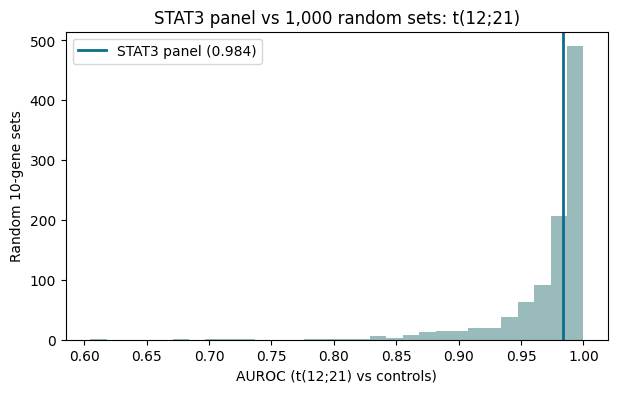

In [22]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 4))
plt.hist(sub_aucs, bins=30, color="#9bb")
plt.axvline(stat3_sub, color="#0B6E8A", lw=2, label=f"STAT3 panel ({stat3_sub:.3f})")
plt.xlabel("AUROC (t(12;21) vs controls)")
plt.ylabel("Random 10-gene sets")
plt.title("STAT3 panel vs 1,000 random sets: t(12;21)")
plt.legend()
plt.savefig("fig5_t1221.png", dpi=200, bbox_inches="tight")
plt.show()

In [23]:
from google.colab import files
files.download("fig5_t1221.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
import sqlite3
import pandas as pd

con = sqlite3.connect("stat3.db")

# Table 1: one row per sample
samples = sel.rename(columns={"group": "group_label"})[["gsm", "group_label", "leukemia_class", "sample_type"]]
samples.to_sql("samples", con, if_exists="replace", index=False)

# Table 2: the 10 panel genes for each sample
expr = ref.drop(columns="group").reset_index()
expr = expr.rename(columns={expr.columns[0]: "gsm"})
expr.to_sql("expression", con, if_exists="replace", index=False)

# The SQL query: average of three genes in each group
query = """
SELECT s.group_label,
       COUNT(*) AS n_samples,
       ROUND(AVG(e.MYC), 4)  AS avg_MYC,
       ROUND(AVG(e.BCL2), 4) AS avg_BCL2,
       ROUND(AVG(e.MCL1), 4) AS avg_MCL1
FROM samples s
JOIN expression e ON s.gsm = e.gsm
GROUP BY s.group_label;
"""
print(pd.read_sql(query, con))

  group_label  n_samples  avg_MYC  avg_BCL2  avg_MCL1
0       B-ALL        563   0.6484    0.5347    0.8085
1     Control         74   0.6637    0.4151    0.8445


In [25]:
print("SQLite version:", sqlite3.sqlite_version)

query2 = """
SELECT leukemia_class, COUNT(*) AS n_samples
FROM samples
GROUP BY leukemia_class
ORDER BY n_samples DESC;
"""
print(pd.read_sql(query2, con))

SQLite version: 3.45.1
                         leukemia_class  n_samples
0       c-ALL/Pre-B-ALL without t(9;22)        237
1          c-ALL/Pre-B-ALL with t(9;22)        122
2  Non-leukemia and healthy bone marrow         74
3           Pro-B-ALL with t(11q23)/MLL         70
4                     ALL with t(12;21)         58
5       ALL with hyperdiploid karyotype         40
6                      ALL with t(1;19)         36


In [26]:
print(pd.read_sql("SELECT * FROM samples LIMIT 5;", con))
print(pd.read_sql("SELECT * FROM expression LIMIT 5;", con))

         gsm group_label               leukemia_class       sample_type
0  GSM329420       B-ALL  Pro-B-ALL with t(11q23)/MLL       bone marrow
1  GSM329421       B-ALL  Pro-B-ALL with t(11q23)/MLL  peripheral blood
2  GSM329422       B-ALL  Pro-B-ALL with t(11q23)/MLL       bone marrow
3  GSM329423       B-ALL  Pro-B-ALL with t(11q23)/MLL  peripheral blood
4  GSM329424       B-ALL  Pro-B-ALL with t(11q23)/MLL       bone marrow
         gsm      BCL2    BCL2L1     BIRC5     CCND1     CCND2    CDC25A  \
0  GSM329420  0.391056  0.553487  0.428582  0.351228  0.537228  0.373599   
1  GSM329421  0.424744  0.566508  0.409937  0.189444  0.419287  0.076822   
2  GSM329422  0.636967  0.533882  0.583470  0.111366  0.368749  0.405106   
3  GSM329423  0.281732  0.492363  0.303923  0.116489  0.520293  0.076847   
4  GSM329424  0.554493  0.475927  0.382678  0.082563  0.623919  0.311534   

       MCL1       MYC      PIM1     SOCS3  
0  0.840188  0.679936  0.691822  0.371761  
1  0.850891  0.732781  